In [2]:

from google.colab import files
import zipfile
import os

uploaded = files.upload()

zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/ecommerce_data')

print("Dataset extracted successfully!")


Saving archive.zip to archive.zip
Dataset extracted successfully!


In [3]:

import pandas as pd
import numpy as np
import os

data_path = '/content/ecommerce_data'

for file in os.listdir(data_path):
    print(file)


olist_order_reviews_dataset.csv
product_category_name_translation.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_sellers_dataset.csv
olist_geolocation_dataset.csv
olist_products_dataset.csv
olist_customers_dataset.csv
olist_orders_dataset.csv


In [4]:

orders = pd.read_csv(
    data_path + '/olist_orders_dataset.csv'
)

customers = pd.read_csv(
    data_path + '/olist_customers_dataset.csv'
)

order_items = pd.read_csv(
    data_path + '/olist_order_items_dataset.csv'
)

products = pd.read_csv(
    data_path + '/olist_products_dataset.csv'
)

payments = pd.read_csv(
    data_path + '/olist_order_payments_dataset.csv'
)

reviews = pd.read_csv(
    data_path + '/olist_order_reviews_dataset.csv'
)

print("All datasets loaded successfully!")


All datasets loaded successfully!


In [5]:

datasets = {
    'Orders': orders,
    'Customers': customers,
    'Order Items': order_items,
    'Products': products,
    'Payments': payments,
    'Reviews': reviews
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")


Orders: (99441, 8)
Customers: (99441, 5)
Order Items: (112650, 7)
Products: (32951, 9)
Payments: (103886, 5)
Reviews: (99224, 7)


In [6]:

for name, df in datasets.items():
    print("\n" + "="*50)
    print(name)
    print("="*50)
    print(df.columns.tolist())
    print(df.head(3))



Orders
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00           2018-08-07 15:27:45   
2          2018-08-08 13:50:00           2018-08-17 18:06:2

In [7]:

for name, df in datasets.items():
    print(f"\n{name}")
    print(df.isnull().sum())



Orders
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Customers
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Order Items
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

Products
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm  

In [8]:


print("Orders - Unique order IDs:",
      orders['order_id'].nunique())

print("Customers - Unique customer IDs:",
      customers['customer_id'].nunique())

print("Products - Unique product IDs:",
      products['product_id'].nunique())


Orders - Unique order IDs: 99441
Customers - Unique customer IDs: 99441
Products - Unique product IDs: 32951


In [9]:

print(orders['order_status'].value_counts())

print("\nOrder status percentage:")
print(
    orders['order_status']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Order status percentage:
order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64


In [10]:

# Create copies of original datasets

orders_clean = orders.copy()
customers_clean = customers.copy()
order_items_clean = order_items.copy()
products_clean = products.copy()
payments_clean = payments.copy()
reviews_clean = reviews.copy()

# Convert date columns into datetime format

date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders_clean[col] = pd.to_datetime(
        orders_clean[col],
        errors='coerce'
    )

# Fill missing product categories

products_clean['product_category_name'] = (
    products_clean['product_category_name']
    .fillna('Unknown')
)

# Check results

print("Missing values after cleaning:")

for name, df in {
    'Orders': orders_clean,
    'Products': products_clean
}.items():
    print(f"\n{name}")
    print(df.isnull().sum())


Missing values after cleaning:

Orders
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Products
product_id                      0
product_category_name           0
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


In [11]:

total_revenue = order_items_clean['price'].sum()

total_orders = orders_clean['order_id'].nunique()

delivered_orders = (
    orders_clean[
        orders_clean['order_status'] == 'delivered'
    ]['order_id'].nunique()
)

average_order_value = (
    total_revenue / total_orders
)

print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Delivered Orders:", delivered_orders)
print("Average Revenue per Order:", round(average_order_value, 2))


Total Revenue: 13591643.7
Total Orders: 99441
Delivered Orders: 96478
Average Revenue per Order: 136.68


In [12]:

# Merge orders with order items

sales_data = order_items_clean.merge(
    orders_clean[['order_id', 'order_purchase_timestamp', 'order_status']],
    on='order_id',
    how='left'
)

# Extract year and month

sales_data['year_month'] = (
    sales_data['order_purchase_timestamp']
    .dt.to_period('M')
    .astype(str)
)

# Monthly revenue

monthly_revenue = (
    sales_data.groupby('year_month')['price']
    .sum()
    .reset_index()
)

monthly_revenue.columns = ['Month', 'Revenue']

monthly_revenue = monthly_revenue.sort_values('Month')

print(monthly_revenue)


      Month     Revenue
0   2016-09      267.36
1   2016-10    49507.66
2   2016-12       10.90
3   2017-01   120312.87
4   2017-02   247303.02
5   2017-03   374344.30
6   2017-04   359927.23
7   2017-05   506071.14
8   2017-06   433038.60
9   2017-07   498031.48
10  2017-08   573971.68
11  2017-09   624401.69
12  2017-10   664219.43
13  2017-11  1010271.37
14  2017-12   743914.17
15  2018-01   950030.36
16  2018-02   844178.71
17  2018-03   983213.44
18  2018-04   996647.75
19  2018-05   996517.68
20  2018-06   865124.31
21  2018-07   895507.22
22  2018-08   854686.33
23  2018-09      145.00


In [15]:

import matplotlib.pyplot as plt
import seaborn as sns

print("Visualization libraries imported successfully!")


Visualization libraries imported successfully!


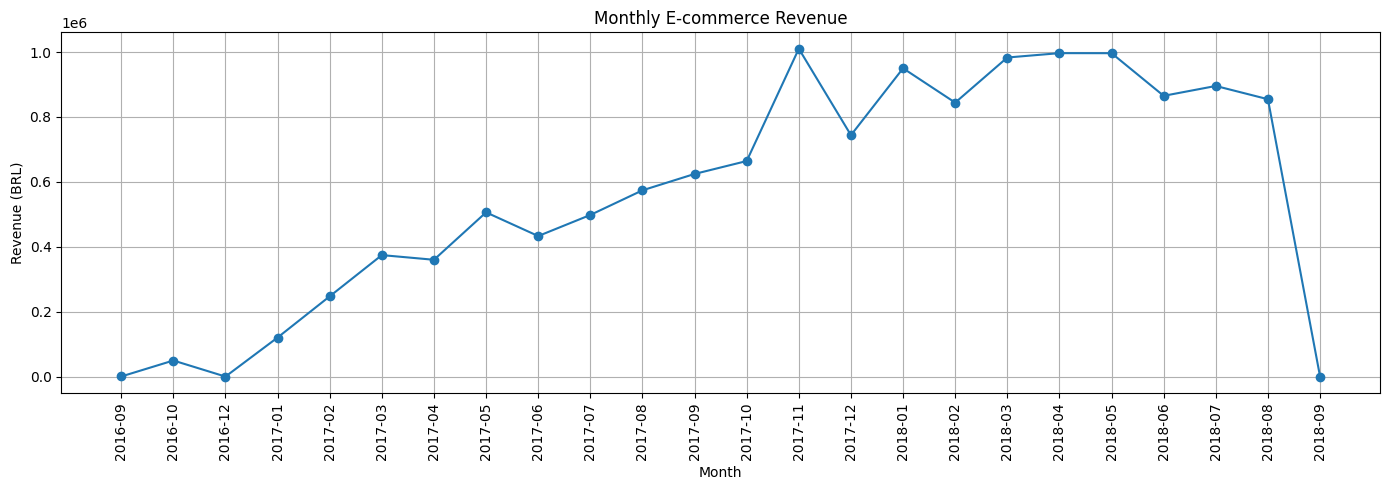

In [16]:

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_revenue['Month'],
    monthly_revenue['Revenue'],
    marker='o'
)

plt.title('Monthly E-commerce Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue (BRL)')
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()


In [17]:

category_data = order_items_clean.merge(
    products_clean[['product_id', 'product_category_name']],
    on='product_id',
    how='left'
)

category_revenue = (
    category_data.groupby('product_category_name')['price']
    .sum()
    .reset_index()
    .sort_values('price', ascending=False)
)

print(category_revenue.head(10))


     product_category_name       price
12            beleza_saude  1258681.34
67      relogios_presentes  1205005.68
14         cama_mesa_banho  1036988.68
33           esporte_lazer   988048.97
45  informatica_acessorios   911954.32
55        moveis_decoracao   729762.49
27              cool_stuff   635290.85
73   utilidades_domesticas   632248.66
9               automotivo   592720.11
41      ferramentas_jardim   485256.46


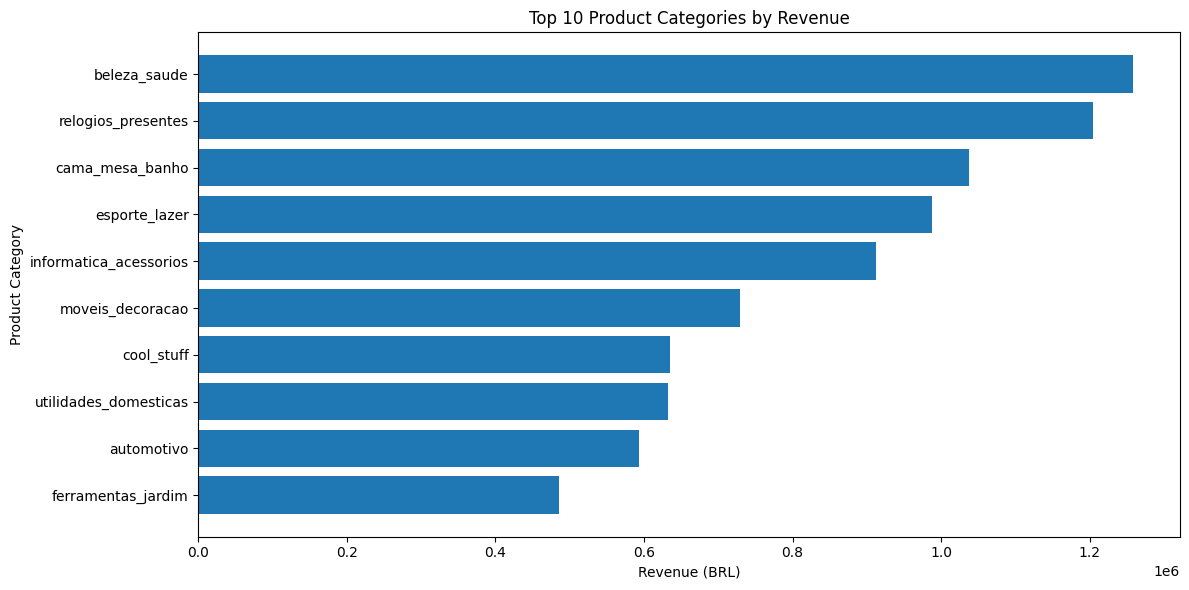

In [18]:

top_categories = category_revenue.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_categories['product_category_name'],
    top_categories['price']
)

plt.title('Top 10 Product Categories by Revenue')
plt.xlabel('Revenue (BRL)')
plt.ylabel('Product Category')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [19]:

customer_orders = orders_clean.merge(
    customers_clean[
        ['customer_id', 'customer_unique_id', 'customer_state']
    ],
    on='customer_id',
    how='left'
)

# Consider delivered orders for purchasing behaviour

delivered_customer_orders = customer_orders[
    customer_orders['order_status'] == 'delivered'
]

total_customers = (
    delivered_customer_orders['customer_unique_id'].nunique()
)

print("Total unique purchasing customers:", total_customers)


Total unique purchasing customers: 93358


In [20]:

customer_purchase_count = (
    delivered_customer_orders
    .groupby('customer_unique_id')['order_id']
    .nunique()
    .reset_index()
)

customer_purchase_count.columns = [
    'customer_unique_id',
    'total_orders'
]

repeat_customers = customer_purchase_count[
    customer_purchase_count['total_orders'] > 1
]

one_time_customers = customer_purchase_count[
    customer_purchase_count['total_orders'] == 1
]

print("Total customers:", len(customer_purchase_count))

print("Repeat customers:", len(repeat_customers))

print("One-time customers:", len(one_time_customers))

repeat_rate = (
    len(repeat_customers) / len(customer_purchase_count)
) * 100

print("Repeat purchase rate:", round(repeat_rate, 2), "%")


Total customers: 93358
Repeat customers: 2801
One-time customers: 90557
Repeat purchase rate: 3.0 %


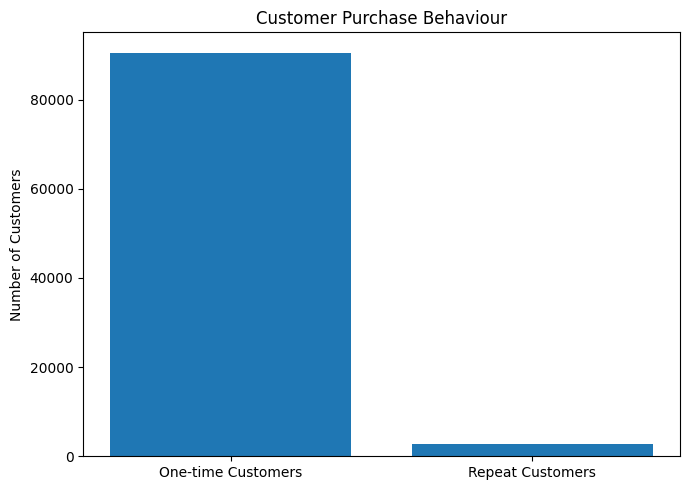

In [21]:

plt.figure(figsize=(7, 5))

plt.bar(
    ['One-time Customers', 'Repeat Customers'],
    [len(one_time_customers), len(repeat_customers)]
)

plt.title('Customer Purchase Behaviour')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()


In [22]:

state_customers = (
    delivered_customer_orders
    .groupby('customer_state')['customer_unique_id']
    .nunique()
    .reset_index()
)

state_customers.columns = [
    'State',
    'Total_Customers'
]

state_customers = state_customers.sort_values(
    'Total_Customers',
    ascending=False
)

print(state_customers.head(10))


   State  Total_Customers
25    SP            39156
18    RJ            11917
10    MG            11001
22    RS             5168
17    PR             4769
23    SC             3449
4     BA             3158
6     DF             2019
7     ES             1928
8     GO             1895


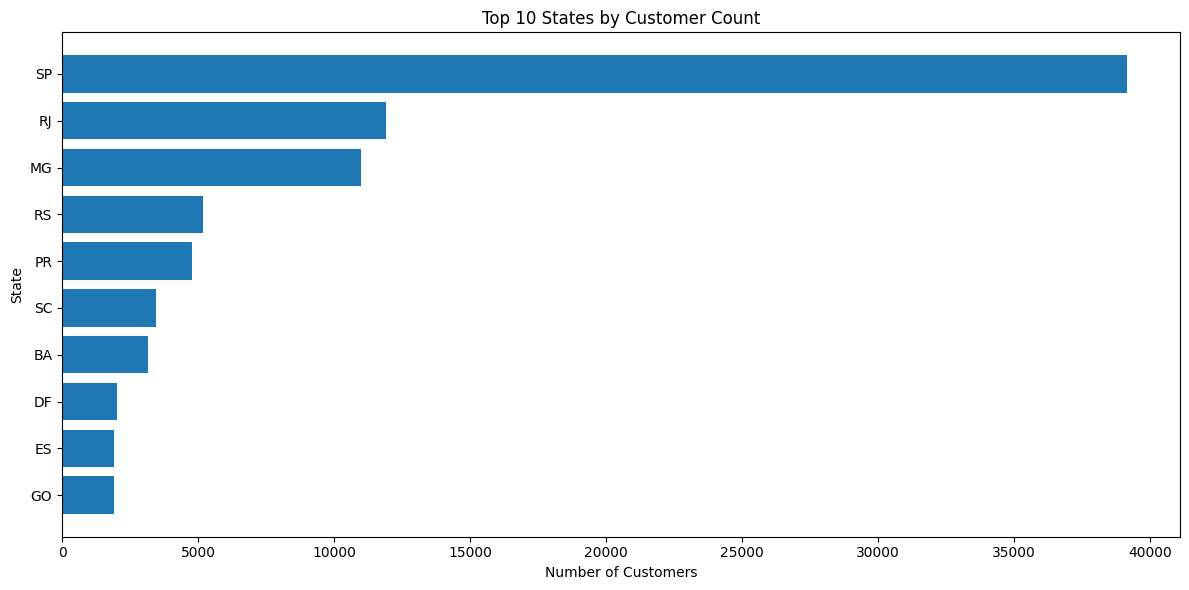

In [23]:

top_states = state_customers.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_states['State'],
    top_states['Total_Customers']
)

plt.title('Top 10 States by Customer Count')
plt.xlabel('Number of Customers')
plt.ylabel('State')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [25]:
sales_data = order_items_clean.merge(
    orders_clean[['order_id', 'order_purchase_timestamp', 'order_status']],
    on='order_id',
    how='left'
)

In [27]:

# First merge Order Items with Orders to get customer_id

state_revenue_data = order_items_clean.merge(
    orders_clean[['order_id', 'customer_id']],
    on='order_id',
    how='left'
)

# Then merge with Customers to get customer_state

state_revenue_data = state_revenue_data.merge(
    customers_clean[['customer_id', 'customer_state']],
    on='customer_id',
    how='left'
)

# Calculate state-wise revenue

state_revenue = (
    state_revenue_data
    .groupby('customer_state')['price']
    .sum()
    .reset_index()
    .sort_values('price', ascending=False)
)

print(state_revenue.head(10))


   customer_state       price
25             SP  5202955.05
18             RJ  1824092.67
10             MG  1585308.03
22             RS   750304.02
17             PR   683083.76
23             SC   520553.34
4              BA   511349.99
6              DF   302603.94
8              GO   294591.95
7              ES   275037.31


In [28]:

delivery_data = orders_clean[
    orders_clean['order_status'] == 'delivered'
].copy()

print("Total delivered orders:", len(delivery_data))

print(
    delivery_data[
        ['order_delivered_customer_date',
         'order_estimated_delivery_date']
    ].head()
)


Total delivered orders: 96478
  order_delivered_customer_date order_estimated_delivery_date
0           2017-10-10 21:25:13                    2017-10-18
1           2018-08-07 15:27:45                    2018-08-13
2           2018-08-17 18:06:29                    2018-09-04
3           2017-12-02 00:28:42                    2017-12-15
4           2018-02-16 18:17:02                    2018-02-26


In [29]:

delivery_data['delivery_delay_days'] = (
    delivery_data['order_delivered_customer_date'] -
    delivery_data['order_estimated_delivery_date']
).dt.total_seconds() / (24 * 60 * 60)

# Positive delay means late delivery
# Zero or negative means on-time or early delivery

delivery_data['delivery_status'] = np.where(
    delivery_data['delivery_delay_days'] > 0,
    'Late',
    'On Time'
)

print(delivery_data['delivery_status'].value_counts())


delivery_status
On Time    88652
Late        7826
Name: count, dtype: int64


In [30]:

total_delivered = len(delivery_data)

late_orders = (
    delivery_data['delivery_status'] == 'Late'
).sum()

on_time_orders = (
    delivery_data['delivery_status'] == 'On Time'
).sum()

late_percentage = late_orders / total_delivered * 100

on_time_percentage = on_time_orders / total_delivered * 100

average_delay = delivery_data.loc[
    delivery_data['delivery_delay_days'] > 0,
    'delivery_delay_days'
].mean()

print("Total Delivered Orders:", total_delivered)
print("Late Orders:", late_orders)
print("On-time/Early Orders:", on_time_orders)
print("Late Delivery Percentage:", round(late_percentage, 2), "%")
print("On-time Delivery Percentage:", round(on_time_percentage, 2), "%")
print("Average Delay (Late Orders Only):", round(average_delay, 2), "days")


Total Delivered Orders: 96478
Late Orders: 7826
On-time/Early Orders: 88652
Late Delivery Percentage: 8.11 %
On-time Delivery Percentage: 91.89 %
Average Delay (Late Orders Only): 9.55 days


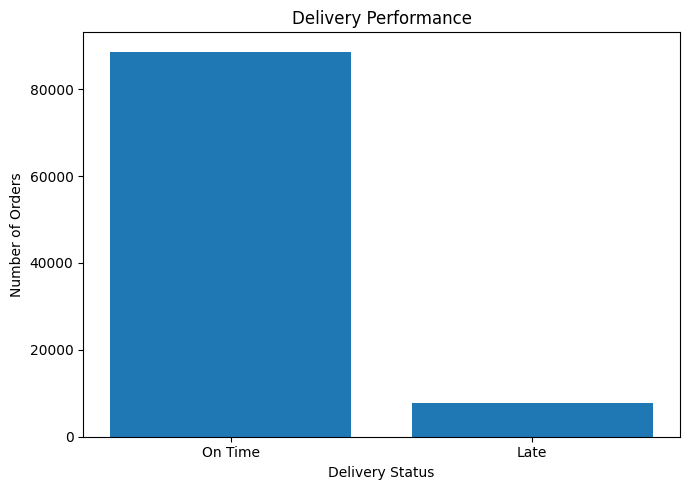

In [31]:

delivery_counts = delivery_data['delivery_status'].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    delivery_counts.index,
    delivery_counts.values
)

plt.title('Delivery Performance')
plt.xlabel('Delivery Status')
plt.ylabel('Number of Orders')
plt.tight_layout()
plt.show()


In [32]:

# Aggregate review scores at order level

order_reviews = (
    reviews_clean
    .groupby('order_id')
    .agg(
        review_score=('review_score', 'mean'),
        review_count=('review_id', 'count')
    )
    .reset_index()
)

# Merge with delivery data

delivery_reviews = delivery_data.merge(
    order_reviews,
    on='order_id',
    how='inner'
)

print("Orders with delivery and review data:",
      len(delivery_reviews))

print(delivery_reviews.head())


Orders with delivery and review data: 95832
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp   order_approved_at  \
0    delivered      2017-10-02 10:56:33 2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37 2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49 2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06 2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39 2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1         

In [33]:

rating_comparison = (
    delivery_reviews
    .groupby('delivery_status')['review_score']
    .agg(['mean', 'count'])
    .reset_index()
)

print(rating_comparison)


  delivery_status      mean  count
0            Late  2.566506   7661
1         On Time  4.294311  88171


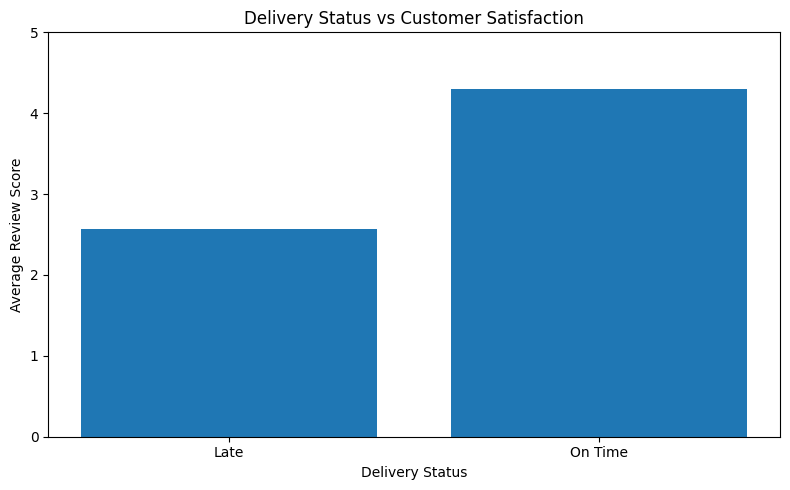

In [34]:

plt.figure(figsize=(8, 5))

plt.bar(
    rating_comparison['delivery_status'],
    rating_comparison['mean']
)

plt.title('Delivery Status vs Customer Satisfaction')
plt.xlabel('Delivery Status')
plt.ylabel('Average Review Score')
plt.ylim(0, 5)
plt.tight_layout()
plt.show()


In [35]:

delivery_reviews['negative_review'] = (
    delivery_reviews['review_score'] <= 2
)

negative_review_analysis = (
    delivery_reviews
    .groupby('delivery_status')['negative_review']
    .mean()
    .mul(100)
    .reset_index(name='Negative_Review_Percentage')
)

print(negative_review_analysis)


  delivery_status  Negative_Review_Percentage
0            Late                   53.987730
1         On Time                    9.187828


In [36]:

payment_analysis = (
    payments_clean
    .groupby('payment_type')
    .agg(
        total_transactions=('order_id', 'count'),
        total_payment=('payment_value', 'sum')
    )
    .reset_index()
    .sort_values('total_payment', ascending=False)
)

print(payment_analysis)


  payment_type  total_transactions  total_payment
1  credit_card               76795    12542084.19
0       boleto               19784     2869361.27
4      voucher                5775      379436.87
2   debit_card                1529      217989.79
3  not_defined                   3           0.00


In [38]:

payment_analysis['revenue_percentage'] = (
    payment_analysis['total_payment'] /
    payment_analysis['total_payment'].sum()
) * 100

print(payment_analysis)


  payment_type  total_transactions  total_payment  revenue_percentage
1  credit_card               76795    12542084.19           78.344584
0       boleto               19784     2869361.27           17.923569
4      voucher                5775      379436.87            2.370166
2   debit_card                1529      217989.79            1.361681
3  not_defined                   3           0.00            0.000000


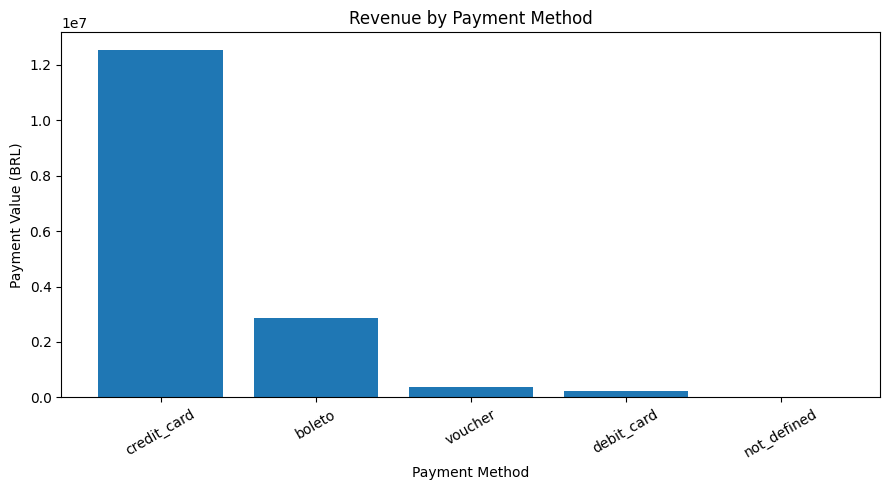

In [37]:

plt.figure(figsize=(9, 5))

plt.bar(
    payment_analysis['payment_type'],
    payment_analysis['total_payment']
)

plt.title('Revenue by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Payment Value (BRL)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [39]:

installment_analysis = (
    payments_clean
    .groupby('payment_installments')
    .agg(
        transactions=('order_id', 'count'),
        total_payment=('payment_value', 'sum')
    )
    .reset_index()
    .sort_values('payment_installments')
)

print(installment_analysis)


    payment_installments  transactions  total_payment
0                      0             2         188.63
1                      1         52546     5907233.36
2                      2         12413     1579283.03
3                      3         10461     1491103.80
4                      4          7098     1163907.61
5                      5          5239      961174.30
6                      6          3920      822611.81
7                      7          1626      305157.39
8                      8          4268     1313423.34
9                      9           644      131015.92
10                    10          5328     2211577.34
11                    11            23        2873.44
12                    12           133       42783.24
13                    13            16        2407.40
14                    14            15        2519.44
15                    15            74       32970.93
16                    16             5        1463.47
17                    17    

In [40]:

import sqlite3

conn = sqlite3.connect('ecommerce_analysis.db')

# Export cleaned datasets into SQL tables

orders_clean.to_sql(
    'orders', conn, if_exists='replace', index=False
)

customers_clean.to_sql(
    'customers', conn, if_exists='replace', index=False
)

order_items_clean.to_sql(
    'order_items', conn, if_exists='replace', index=False
)

products_clean.to_sql(
    'products', conn, if_exists='replace', index=False
)

payments_clean.to_sql(
    'payments', conn, if_exists='replace', index=False
)

reviews_clean.to_sql(
    'reviews', conn, if_exists='replace', index=False
)

print("All tables successfully imported into SQLite!")


All tables successfully imported into SQLite!


In [41]:

def run_query(query):
    return pd.read_sql_query(query, conn)


In [42]:

query = """
SELECT
    strftime('%Y-%m', o.order_purchase_timestamp) AS month,
    ROUND(SUM(oi.price), 2) AS monthly_revenue
FROM orders o
JOIN order_items oi
    ON o.order_id = oi.order_id
GROUP BY month
ORDER BY month;
"""

monthly_sql = run_query(query)

print(monthly_sql)


      month  monthly_revenue
0   2016-09           267.36
1   2016-10         49507.66
2   2016-12            10.90
3   2017-01        120312.87
4   2017-02        247303.02
5   2017-03        374344.30
6   2017-04        359927.23
7   2017-05        506071.14
8   2017-06        433038.60
9   2017-07        498031.48
10  2017-08        573971.68
11  2017-09        624401.69
12  2017-10        664219.43
13  2017-11       1010271.37
14  2017-12        743914.17
15  2018-01        950030.36
16  2018-02        844178.71
17  2018-03        983213.44
18  2018-04        996647.75
19  2018-05        996517.68
20  2018-06        865124.31
21  2018-07        895507.22
22  2018-08        854686.33
23  2018-09           145.00


In [44]:

query = """
SELECT
    p.product_category_name,
    ROUND(SUM(oi.price), 2) AS total_revenue
FROM order_items oi
JOIN products p
    ON oi.product_id = p.product_id
GROUP BY p.product_category_name
ORDER BY total_revenue DESC
LIMIT 10;
"""

top_categories_sql = run_query(query)

print(top_categories_sql)



    product_category_name  total_revenue
0            beleza_saude     1258681.34
1      relogios_presentes     1205005.68
2         cama_mesa_banho     1036988.68
3           esporte_lazer      988048.97
4  informatica_acessorios      911954.32
5        moveis_decoracao      729762.49
6              cool_stuff      635290.85
7   utilidades_domesticas      632248.66
8              automotivo      592720.11
9      ferramentas_jardim      485256.46


In [45]:

query = """
SELECT
    c.customer_unique_id,
    ROUND(SUM(oi.price), 2) AS total_spending,
    COUNT(DISTINCT o.order_id) AS total_orders
FROM orders o
JOIN customers c
    ON o.customer_id = c.customer_id
JOIN order_items oi
    ON o.order_id = oi.order_id
WHERE o.order_status = 'delivered'
GROUP BY c.customer_unique_id
ORDER BY total_spending DESC
LIMIT 10;
"""

top_customers = run_query(query)

print(top_customers)


                 customer_unique_id  total_spending  total_orders
0  0a0a92112bd4c708ca5fde585afaa872         13440.0             1
1  da122df9eeddfedc1dc1f5349a1a690c          7388.0             2
2  763c8b1c9c68a0229c42c9fc6f662b93          7160.0             1
3  dc4802a71eae9be1dd28f5d788ceb526          6735.0             1
4  459bef486812aa25204be022145caa62          6729.0             1
5  ff4159b92c40ebe40454e3e6a7c35ed6          6499.0             1
6  4007669dec559734d6f53e029e360987          5934.6             1
7  eebb5dda148d3893cdaf5b5ca3040ccb          4690.0             1
8  48e1ac109decbb87765a3eade6854098          4590.0             1
9  a229eba70ec1c2abef51f04987deb7a5          4400.0             1


In [46]:
query = """
WITH customer_orders AS (
    SELECT
        c.customer_unique_id,
        COUNT(DISTINCT o.order_id) AS total_orders
    FROM customers c
    JOIN orders o
        ON c.customer_id = o.customer_id
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_unique_id
)

SELECT
    COUNT(*) AS total_customers,

    SUM(CASE
        WHEN total_orders > 1 THEN 1
        ELSE 0
    END) AS repeat_customers,

    ROUND(
        100.0 * SUM(CASE
            WHEN total_orders > 1 THEN 1
            ELSE 0
        END) / COUNT(*), 2
    ) AS repeat_purchase_rate

FROM customer_orders;
"""

run_query(query)

,total_customers,repeat_customers,repeat_purchase_rate
0,93358,2801,3.0


In [47]:
query = """
SELECT
    ROUND(SUM(payment_value) / COUNT(DISTINCT order_id), 2) AS average_order_value
FROM payments;
"""

run_query(query)

,average_order_value
0,160.99


In [48]:
query = """
WITH monthly_revenue AS (
    SELECT
        strftime('%Y-%m', o.order_purchase_timestamp) AS month,
        SUM(p.payment_value) AS revenue
    FROM orders o
    JOIN payments p
        ON o.order_id = p.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY month
),

revenue_growth AS (
    SELECT
        month,
        ROUND(revenue, 2) AS revenue,

        LAG(revenue) OVER (
            ORDER BY month
        ) AS previous_month_revenue

    FROM monthly_revenue
)

SELECT
    month,
    revenue,
    ROUND(previous_month_revenue, 2) AS previous_month_revenue,

    ROUND(
        (revenue - previous_month_revenue)
        * 100.0 / previous_month_revenue, 2
    ) AS growth_percentage

FROM revenue_growth
ORDER BY month;
"""

run_query(query)

,month,revenue,previous_month_revenue,growth_percentage
0,2016-10,46566.71,NaN,NaN
1,2016-12,19.62,46566.71,-99.96
2,2017-01,127545.67,19.62,649979.87
3,2017-02,271298.65,127545.67,112.71
4,2017-03,414369.39,271298.65,52.74
5,2017-04,390952.18,414369.39,-5.65
6,2017-05,567066.73,390952.18,45.05
7,2017-06,490225.60,567066.73,-13.55
8,2017-07,566403.93,490225.60,15.54
9,2017-08,646000.61,566403.93,14.05


In [49]:
query = """
SELECT
    COUNT(*) AS total_delivered_orders,

    SUM(CASE
        WHEN order_delivered_customer_date >
             order_estimated_delivery_date
        THEN 1 ELSE 0
    END) AS late_orders,

    SUM(CASE
        WHEN order_delivered_customer_date <=
             order_estimated_delivery_date
        THEN 1 ELSE 0
    END) AS on_time_orders,

    ROUND(
        100.0 * SUM(CASE
            WHEN order_delivered_customer_date >
                 order_estimated_delivery_date
            THEN 1 ELSE 0
        END) / COUNT(*), 2
    ) AS late_delivery_percentage,

    ROUND(
        AVG(
            julianday(order_delivered_customer_date) -
            julianday(order_purchase_timestamp)
        ), 2
    ) AS average_delivery_days

FROM orders
WHERE order_status = 'delivered';
"""

run_query(query)

,total_delivered_orders,late_orders,on_time_orders,late_delivery_percentage,average_delivery_days
0,96478,7826,88644,8.11,12.56


In [50]:
query = """
SELECT
    COUNT(*) AS total_delivered_orders,

    SUM(CASE
        WHEN order_delivered_customer_date >
             order_estimated_delivery_date
        THEN 1 ELSE 0
    END) AS late_orders,

    SUM(CASE
        WHEN order_delivered_customer_date <=
             order_estimated_delivery_date
        THEN 1 ELSE 0
    END) AS on_time_orders,

    ROUND(
        100.0 * SUM(CASE
            WHEN order_delivered_customer_date >
                 order_estimated_delivery_date
            THEN 1 ELSE 0
        END) / COUNT(*), 2
    ) AS late_delivery_percentage,

    ROUND(
        AVG(
            julianday(order_delivered_customer_date) -
            julianday(order_purchase_timestamp)
        ), 2
    ) AS average_delivery_days

FROM orders
WHERE order_status = 'delivered';
"""

run_query(query)

,total_delivered_orders,late_orders,on_time_orders,late_delivery_percentage,average_delivery_days
0,96478,7826,88644,8.11,12.56


In [51]:
query = """
WITH product_sales AS (
    SELECT
        oi.product_id,
        COUNT(DISTINCT oi.order_id) AS total_orders,
        SUM(oi.price) AS total_revenue
    FROM order_items oi
    JOIN orders o
        ON oi.order_id = o.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY oi.product_id
),

ranked_products AS (
    SELECT
        product_id,
        total_orders,
        total_revenue,

        RANK() OVER (
            ORDER BY total_revenue DESC
        ) AS product_rank

    FROM product_sales
)

SELECT
    product_id,
    total_orders,
    ROUND(total_revenue, 2) AS total_revenue,
    product_rank
FROM ranked_products
ORDER BY product_rank
LIMIT 10;
"""

run_query(query)

,product_id,total_orders,total_revenue,product_rank
0,bb50f2e236e5eea0100680137654686c,186,63560.00,1
1,6cdd53843498f92890544667809f1595,148,53652.30,2
2,d6160fb7873f184099d9bc95e30376af,33,45949.35,3
3,d1c427060a0f73f6b889a5c7c61f2ac4,313,45620.56,4
4,99a4788cb24856965c36a24e339b6058,456,42049.66,5
5,3dd2a17168ec895c781a9191c1e95ad7,253,40782.80,6
6,25c38557cf793876c5abdd5931f922db,38,38907.32,7
7,5f504b3a1c75b73d6151be81eb05bdc9,63,37733.90,8
8,53b36df67ebb7c41585e8d54d6772e08,304,37454.63,9
9,aca2eb7d00ea1a7b8ebd4e68314663af,425,37104.30,10


In [53]:
query = """
SELECT name
FROM sqlite_master
WHERE type = 'table';
"""

run_query(query)

,name
0,orders
1,customers
2,order_items
3,products
4,payments
5,reviews


In [54]:
run_query("PRAGMA table_info(products);")

,cid,name,type,notnull,dflt_value,pk
0,0,product_id,TEXT,0,None,0
1,1,product_category_name,TEXT,0,None,0
2,2,product_name_lenght,REAL,0,None,0
3,3,product_description_lenght,REAL,0,None,0
4,4,product_photos_qty,REAL,0,None,0
5,5,product_weight_g,REAL,0,None,0
6,6,product_length_cm,REAL,0,None,0
7,7,product_height_cm,REAL,0,None,0
8,8,product_width_cm,REAL,0,None,0


In [55]:
query = """
WITH product_sales AS (
    SELECT
        oi.product_id,
        COUNT(DISTINCT oi.order_id) AS total_orders,
        SUM(oi.price) AS total_revenue
    FROM order_items oi
    JOIN orders o
        ON oi.order_id = o.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY oi.product_id
),

ranked_products AS (
    SELECT
        *,
        RANK() OVER (
            ORDER BY total_revenue DESC
        ) AS product_rank
    FROM product_sales
)

SELECT
    rp.product_id,
    COALESCE(p.product_category_name, 'Unknown') AS category,
    rp.total_orders,
    ROUND(rp.total_revenue, 2) AS total_revenue,
    rp.product_rank

FROM ranked_products rp
LEFT JOIN products p
    ON rp.product_id = p.product_id

WHERE rp.product_rank <= 10
ORDER BY rp.product_rank;
"""

run_query(query)

,product_id,category,total_orders,total_revenue,product_rank
0,bb50f2e236e5eea0100680137654686c,beleza_saude,186,63560.00,1
1,6cdd53843498f92890544667809f1595,beleza_saude,148,53652.30,2
2,d6160fb7873f184099d9bc95e30376af,pcs,33,45949.35,3
3,d1c427060a0f73f6b889a5c7c61f2ac4,informatica_acessorios,313,45620.56,4
4,99a4788cb24856965c36a24e339b6058,cama_mesa_banho,456,42049.66,5
5,3dd2a17168ec895c781a9191c1e95ad7,informatica_acessorios,253,40782.80,6
6,25c38557cf793876c5abdd5931f922db,bebes,38,38907.32,7
7,5f504b3a1c75b73d6151be81eb05bdc9,cool_stuff,63,37733.90,8
8,53b36df67ebb7c41585e8d54d6772e08,relogios_presentes,304,37454.63,9
9,aca2eb7d00ea1a7b8ebd4e68314663af,moveis_decoracao,425,37104.30,10


In [56]:
query = """
WITH customer_spending AS (
    SELECT
        c.customer_unique_id,
        SUM(p.payment_value) AS total_spending,
        COUNT(DISTINCT o.order_id) AS total_orders
    FROM customers c
    JOIN orders o
        ON c.customer_id = o.customer_id
    JOIN payments p
        ON o.order_id = p.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_unique_id
),

segmented_customers AS (
    SELECT
        customer_unique_id,
        total_spending,
        total_orders,
        CASE
            WHEN total_spending > 1000 THEN 'High Value'
            WHEN total_spending >= 250 THEN 'Medium Value'
            ELSE 'Low Value'
        END AS customer_segment
    FROM customer_spending
)

SELECT
    customer_segment,
    COUNT(*) AS total_customers,
    ROUND(AVG(total_spending), 2) AS average_spending,
    ROUND(AVG(total_orders), 2) AS average_orders
FROM segmented_customers
GROUP BY customer_segment
ORDER BY average_spending DESC;
"""

run_query(query)

,customer_segment,total_customers,average_spending,average_orders
0,High Value,1149,1584.30,1.11
1,Medium Value,12517,423.21,1.11
2,Low Value,79691,104.21,1.02


In [57]:
query = """
WITH customer_spending AS (
    SELECT
        c.customer_unique_id,
        SUM(p.payment_value) AS total_spending
    FROM customers c
    JOIN orders o
        ON c.customer_id = o.customer_id
    JOIN payments p
        ON o.order_id = p.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_unique_id
),

segmented AS (
    SELECT
        total_spending,
        CASE
            WHEN total_spending > 1000 THEN 'High Value'
            WHEN total_spending >= 250 THEN 'Medium Value'
            ELSE 'Low Value'
        END AS segment
    FROM customer_spending
)

SELECT
    segment,
    COUNT(*) AS customers,
    ROUND(SUM(total_spending), 2) AS total_revenue,
    ROUND(
        100.0 * SUM(total_spending) /
        (SELECT SUM(total_spending) FROM segmented), 2
    ) AS revenue_contribution_percentage

FROM segmented
GROUP BY segment
ORDER BY total_revenue DESC;
"""

run_query(query)

,segment,customers,total_revenue,revenue_contribution_percentage
0,Low Value,79691,8304727.08,53.85
1,Medium Value,12517,5297372.66,34.35
2,High Value,1149,1820362.03,11.80
